# 13 · ARL sweep: does the matched coupling gain grow towards its long-delay limit?

**Background (notebook 12).** For matched oracle detectors, the coupling gain at ARL 1000 is predicted to within a factor of 2 in all 30 cases. The prediction treats each detector as a Gaussian CUSUM with its zero-frequency information rate and uses Siegmund's approximation at that ARL ($G_{\text{fin}}$). The asymptotic ratio of rates over-predicts, because at ARL 1000 the coupled detector's delay is only a few windows and a CUSUM's fixed overheads dominate.

**Predictions, written before this notebook was run.** That explanation implies something new. As the ARL grows, every delay lengthens, the overheads matter less, and the gain should rise towards the ratio of information rates. For the matched oracle detectors of notebook 12, at ARL 100, 1000 and 10 000 windows:
- **P1.** In the four settings with shared slow noise, the measured gain rises with the ARL for each fault.
- **P2.** At every ARL, the finite-ARL prediction $G_{\text{fin}}(\text{ARL})$ is within a factor of 2 of the measured gain.
- **P3.** In the control, the gain stays at its no-coupling value (about 1, or about 2 for the weight misconfiguration, which moves two slices) at every ARL.

**Which limit?** As the ARL grows, $G_{\text{fin}}$ tends to the ratio of the two detectors' rates, $G_{\text{inn}} = \lVert\delta\rVert^2 / (d_{j^*}^2/\Sigma_{LR,j^*j^*})$, where the coupled rate is that of the VAR innovations. In theory $G_{\text{inn}} = G_{\text{DC}}$ (notebook 10). In practice the VAR-implied and Bartlett estimates differ by up to 3× in high load and the new mix (notebook 11). So we report both limits and make no prediction about which one the gain approaches.

**Changes from notebook 12, needed for large ARLs.**
- Calibration uses 48 fault-free runs of 1000 s per setting (480 000 windows, about 48 false alarms at ARL 10 000).
- Fault runs last 63 s, with the fault at 3 s, so delays up to 60 s are observed. The fault comes earlier than in notebook 12 (10 s) because at ARL 100 a fault at 10 s would follow a false alarm in about 63% of runs. At 3 s that is about a quarter of runs at ARL 100 and 3% at ARL 1000; those runs are dropped, as before. There are 64 runs per case (32 before), so the numbers at ARL 1000 differ slightly from notebook 12's.
- Only the matched detectors are used. Settings, faults and seeds are those of notebooks 11–12. Strengths 0.5 and 1 are left out: in notebook 12 they never gave a usable case, because either the ARL could not be reached or the delays sat at the one-window floor.
- A case enters the comparison only if both detectors reach every target ARL to within 5%, and the single-slice detector finds at least 80% of faults at every ARL. All ARLs are thus compared on the same cases.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import CUSUMBank, StreamModel, VARModel, long_run_cov, stream_array
from slicead.eval import calibrate_threshold, first_alarms, summarize_delays

SEED = 20261022                       # same seeds as notebooks 05-12
OUT = Path("../results/13_arl_sweep")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"13_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"13_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"13_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

SETTINGS = ["default", "high_load", "new_mix", "light_load", "control"]
NICE_SET = {"default": "default", "high_load": "high load", "new_mix": "new mix", "light_load": "light load",
            "control": "control"}
COLOR = {"default": BLUE, "high_load": ORANGE, "new_mix": AQUA, "light_load": YELLOW, "control": MUTED}
LAT = [(s, "latency_ms") for s in ["eMBB", "URLLC", "mMTC"]]
ARLS = [100, 1000, 10000]
CHANGE_S, WINDOW_S = 3.0, 0.1
N_FAULT_W, N_FAULT_RUNS, HORIZON_W = 630, 64, 600   # 63 s runs, fault at 3 s, 60 s horizon
N_CAL_RUNS, N_CAL_W = 48, 10000            # 480 000 fault-free windows for calibration
STRENGTHS = [0.03, 0.1, 0.25]              # 0.5 and 1 gave no usable case in notebook 12; seeds unchanged
SCEN = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
ALL = list(SCEN)
LOCAL = ["urllc_surge", "mmtc_storm", "urllc_weight_misconfig"]
NICE = {"urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm", "urllc_weight_misconfig": "URLLC weight misconfig."}

def siegmund(D, h):
    """Siegmund's ARL / delay of a CUSUM with N(D, 1) increments and threshold h (notebook 01)."""
    b = h + 1.166
    return b if abs(D) < 1e-9 else (np.expm1(-2 * D * b) + 2 * D * b) / (2 * D**2)

def predicted_delay_s(kl, arl):
    """Delay of a matched Gaussian CUSUM with signal-to-noise mu = sqrt(2 KL) at the given ARL, in seconds."""
    mu = np.sqrt(2 * kl)
    with np.errstate(over="ignore"):
        f = lambda h: siegmund(-mu / 2, h) - arl
        h = 0.0 if f(0.0) >= 0 else brentq(f, 0.0, 1e4)     # very strong faults: any excursion alarms
        return WINDOW_S * max(1.0, siegmund(mu / 2, h))

## 1. Matched oracle detectors at three ARLs

`run_setting` is notebook 12's code with the two matched detectors only. Each detector is calibrated separately to each target ARL on the long fault-free runs and then applied to the fault runs. Each setting's rows are saved to `results/13_arl_sweep/rows_<setting>.csv` and reused on a re-run. Delete them to recompute; the seeds make the result identical.

In [2]:
def run_setting(name):
    t0 = time.time()
    cfg = load_config(f"../configs/sim_{name}.yaml")
    Xtr = stream_array(simulate(cfg, n_windows=3000, n_runs=8, seed=SEED), LAT)
    Xcal = stream_array(simulate(cfg, n_windows=N_CAL_W, n_runs=N_CAL_RUNS, seed=SEED + 2), LAT)
    ar1 = StreamModel().fit(Xtr)
    var = VARModel(max_p=30).fit(Xtr)
    Zcal, Vcal = ar1.whiten(Xcal), var.whiten(Xcal)
    del Xcal
    SLR = long_run_cov(ar1.whiten(Xtr), 50)
    print(f"{name}: simulated in {time.time() - t0:.0f} s", flush=True)
    rows = []
    for scen in LOCAL:
        i = ALL.index(scen)
        for j, s in enumerate(STRENGTHS):
            res = simulate(cfg, n_windows=N_FAULT_W, n_runs=N_FAULT_RUNS, seed=SEED + 100 + 10 * i + j,
                           faults=[Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in SCEN[scen]])
            X = stream_array(res, LAT)
            Z, V = ar1.whiten(X), var.whiten(X)
            nu = res.fault_window
            d = Z[:, nu + 20:].mean(axis=(0, 1)) - Z[:, 5:nu].mean(axis=(0, 1))          # skip the VAR's start-up windows
            delta = V[:, nu + 20:].mean(axis=(0, 1)) - V[:, 5:nu].mean(axis=(0, 1))
            rates = d**2 / np.diag(SLR)
            js = int(np.argmax(rates))
            kl_ps, kl_var, kl_dc = rates[js] / 2, (delta @ np.linalg.solve(var.Sigma_e, delta)) / 2, (d @ np.linalg.solve(SLR, d)) / 2
            dets = {"PS": (CUSUMBank.matched([d[js]], [[1.0]]), Zcal[:, :, [js]], Z[:, :, [js]]),
                    "VAR": (CUSUMBank.matched(delta, var.Sigma_e), Vcal, V)}
            for arl in ARLS:
                row = dict(setting=name, scenario=scen, strength=s, arl=arl, best_slice=js,
                           KL_ps=kl_ps, KL_var=kl_var, KL_dc=kl_dc)
                for dn, (det, Zc, Zt) in dets.items():
                    h, got = calibrate_threshold(det, Zc, arl)
                    t, _ = first_alarms(det, Zt, h)
                    out = summarize_delays(t, nu, HORIZON_W, WINDOW_S)
                    row.update({f"{dn} delay": out["delay_mean_s"], f"{dn} found": out["detected"],
                                f"{dn} false alarm": out["false_alarm"], f"{dn} arl": got})
                rows.append(row)
    print(f"{name}: done in {time.time() - t0:.0f} s", flush=True)
    return rows

def setting_rows(name):
    """Each setting's rows are saved when done and reused on a re-run (same code, same seeds), so an
    interrupted run, e.g. by the laptop sleeping, loses at most one setting."""
    path = OUT / f"rows_{name}.csv"
    if not path.exists():
        pd.DataFrame(run_setting(name)).to_csv(path, index=False)
    return pd.read_csv(path)

res = pd.concat([setting_rows(n) for n in SETTINGS], ignore_index=True)
res["arl_ok"] = (np.abs(np.log(res["PS arl"] / res.arl)) < 0.05) & (np.abs(np.log(res["VAR arl"] / res.arl)) < 0.05)
res["gain"] = res["PS delay"] / res["VAR delay"]
res["G_fin"] = [predicted_delay_s(a, r) / predicted_delay_s(b, r) for a, b, r in zip(res.KL_ps, res.KL_var, res.arl)]
res["G_inn"] = res.KL_var / res.KL_ps
res["G_dc"] = res.KL_dc / res.KL_ps
res.to_csv(OUT / "arl_sweep.csv", index=False)

key = ["setting", "scenario", "strength"]
ok = res.groupby(key).apply(lambda g: bool(g.arl_ok.all() and (g["PS found"] >= 0.8).all()), include_groups=False)
cases = ok[ok].index
use = res.set_index(key).loc[cases].reset_index()
print(f"cases usable at all three ARLs: {len(cases)} of {len(ok)}")
use.pivot_table(index=key, columns="arl", values=["gain", "G_fin"]).round(2)

cases usable at all three ARLs: 23 of 45


G_fin                 gain         \
arl                                         100    1000   10000  100    1000    
setting    scenario               strength                                      
control    mmtc_storm             0.03       0.94   0.93   0.93   1.04   1.01   
                                  0.10       1.00   0.93   0.93   1.00   1.01   
           urllc_surge            0.03       0.98   0.98   0.97   0.97   1.04   
                                  0.10       0.98   0.98   0.98   1.09   1.03   
           urllc_weight_misconfig 0.03       1.60   1.74   1.81   1.59   1.80   
                                  0.10       1.30   1.69   1.72   1.37   1.79   
default    mmtc_storm             0.10       7.97  12.57  15.82   9.44  13.65   
                                  0.25       8.45  15.50  21.05   5.62  10.63   
           urllc_surge            0.10       7.60  11.61  14.38   4.16   9.62   
                                  0.25       6.52  11.41  16.50   3.67   8.40   
           urllc_weight_misconfig 0.10      17.88  29.45  36.86  12.01  16.05   
high_load  mmtc_storm             0.10       9.10  14.50  18.34   4.99  10.95   
                                  0.25       8.28  15.13  22.36   2.80   9.68   
           urllc_surge            0.10       8.69  13.62  17.08   5.10   9.74   
           urllc_weight_misconfig 0.03       7.85  16.48  24.96   8.72  16.04   
                                  0.10      15.86  28.44  35.06   6.18  19.18   
light_load mmtc_storm             0.10       9.23  14.89  18.98   7.45  12.73   
           urllc_surge            0.10       5.97   8.54  10.21   5.23   7.55   
                                  0.25       5.47   9.31  13.15   4.66   5.50   
           urllc_weight_misconfig 0.03       8.21  18.00  28.13   5.15  13.06   
                                  0.10      15.28  22.80  27.92  10.92  14.58   
new_mix    mmtc_storm             0.10      16.73  29.68  39.79  12.64  27.56   
           urllc_surge            0.10      19.17  31.51  40.55  12.22  19.11   

                                                   
arl                                         10000  
setting    scenario               strength         
control    mmtc_storm             0.03       1.00  
                                  0.10       1.00  
           urllc_surge            0.03       1.03  
                                  0.10       1.03  
           urllc_weight_misconfig 0.03       2.03  
                                  0.10       1.60  
default    mmtc_storm             0.10      19.16  
                                  0.25      18.94  
           urllc_surge            0.10      12.78  
                                  0.25      12.77  
           urllc_weight_misconfig 0.10      26.12  
high_load  mmtc_storm             0.10      13.97  
                                  0.25      16.21  
           urllc_surge            0.10      13.59  
           urllc_weight_misconfig 0.03      22.98  
                                  0.10      25.56  
light_load mmtc_storm             0.10      15.81  
           urllc_surge            0.10       9.11  
                                  0.25       7.73  
           urllc_weight_misconfig 0.03      17.60  
                                  0.10      19.06  
new_mix    mmtc_storm             0.10      32.21  
           urllc_surge            0.10      26.15

## 2. P1 and P3: does the gain rise with the ARL?

In [3]:
wide = use.pivot_table(index=key, columns="arl", values="gain")
lims = use.groupby(key)[["G_inn", "G_dc"]].first()
trend = wide.join(lims)
trend["rises"] = (trend[ARLS[1]] > trend[ARLS[0]]) & (trend[ARLS[2]] > trend[ARLS[1]])
trend["rise_100_to_10000"] = trend[ARLS[2]] / trend[ARLS[0]]
gfin = use.pivot_table(index=key, columns="arl", values="G_fin")
trend["predicted_rise"] = gfin[ARLS[2]] / gfin[ARLS[0]]
trend.to_csv(OUT / "trend.csv")
coupled = trend.loc[[c for c in trend.index if c[0] != "control"]]
control = trend.loc[[c for c in trend.index if c[0] == "control"]]
print(f"P1: gain rises monotonically in {int(coupled.rises.sum())} of {len(coupled)} coupled cases; "
      f"median rise ARL 100 -> 10 000: x{coupled.rise_100_to_10000.median():.2f}")
print(f"predicted rise (G_fin) ARL 100 -> 10 000: median x{coupled.predicted_rise.median():.2f}, "
      f"range x{coupled.predicted_rise.min():.2f}-x{coupled.predicted_rise.max():.2f}")
print(f"P3: control gains range {control[ARLS].min().min():.2f} - {control[ARLS].max().max():.2f}")
trend.round(2)

P1: gain rises monotonically in 17 of 17 coupled cases; median rise ARL 100 -> 10 000: x2.64
predicted rise (G_fin) ARL 100 -> 10 000: median x2.12, range x1.71-x3.42
P3: control gains range 0.97 - 2.03


100   1000  10000  G_inn   G_dc  \
setting    scenario               strength                                      
control    mmtc_storm             0.03       1.04   1.01   1.00   0.92   1.01   
                                  0.10       1.00   1.01   1.00   0.92   1.01   
           urllc_surge            0.03       0.97   1.04   1.03   0.97   1.02   
                                  0.10       1.09   1.03   1.03   0.97   1.02   
           urllc_weight_misconfig 0.03       1.59   1.80   2.03   1.98   1.98   
                                  0.10       1.37   1.79   1.60   1.83   1.82   
default    mmtc_storm             0.10       9.44  13.65  19.16  25.57  18.54   
                                  0.25       5.62  10.63  18.94  31.35  22.67   
           urllc_surge            0.10       4.16   9.62  12.78  22.63  17.79   
                                  0.25       3.67   8.40  12.77  25.21  19.36   
           urllc_weight_misconfig 0.10      12.01  16.05  26.12  63.10  47.20   
high_load  mmtc_storm             0.10       4.99  10.95  13.97  30.14  13.84   
                                  0.25       2.80   9.68  16.21  33.51  15.25   
           urllc_surge            0.10       5.10   9.74  13.59  27.65  14.82   
           urllc_weight_misconfig 0.03       8.72  16.04  22.98  51.16  24.56   
                                  0.10       6.18  19.18  25.56  58.73  30.19   
light_load mmtc_storm             0.10       7.45  12.73  15.81  31.54  27.61   
           urllc_surge            0.10       5.23   7.55   9.11  15.06  12.92   
                                  0.25       4.66   5.50   7.73  18.12  15.65   
           urllc_weight_misconfig 0.03       5.15  13.06  17.60  60.33  53.47   
                                  0.10      10.92  14.58  19.06  45.64  39.77   
new_mix    mmtc_storm             0.10      12.64  27.56  32.21  74.14  23.02   
           urllc_surge            0.10      12.22  19.11  26.15  72.22  24.51   

                                            rises  rise_100_to_10000  \
setting    scenario               strength                             
control    mmtc_storm             0.03      False               0.96   
                                  0.10      False               1.00   
           urllc_surge            0.03      False               1.07   
                                  0.10      False               0.94   
           urllc_weight_misconfig 0.03       True               1.28   
                                  0.10      False               1.17   
default    mmtc_storm             0.10       True               2.03   
                                  0.25       True               3.37   
           urllc_surge            0.10       True               3.07   
                                  0.25       True               3.48   
           urllc_weight_misconfig 0.10       True               2.17   
high_load  mmtc_storm             0.10       True               2.80   
                                  0.25       True               5.79   
           urllc_surge            0.10       True               2.67   
           urllc_weight_misconfig 0.03       True               2.64   
                                  0.10       True               4.14   
light_load mmtc_storm             0.10       True               2.12   
           urllc_surge            0.10       True               1.74   
                                  0.25       True               1.66   
           urllc_weight_misconfig 0.03       True               3.42   
                                  0.10       True               1.74   
new_mix    mmtc_storm             0.10       True               2.55   
           urllc_surge            0.10       True               2.14   

                                            predicted_rise  
setting    scenario               strength                  
control    mmtc_storm             0.03                0.99  
                                  0.

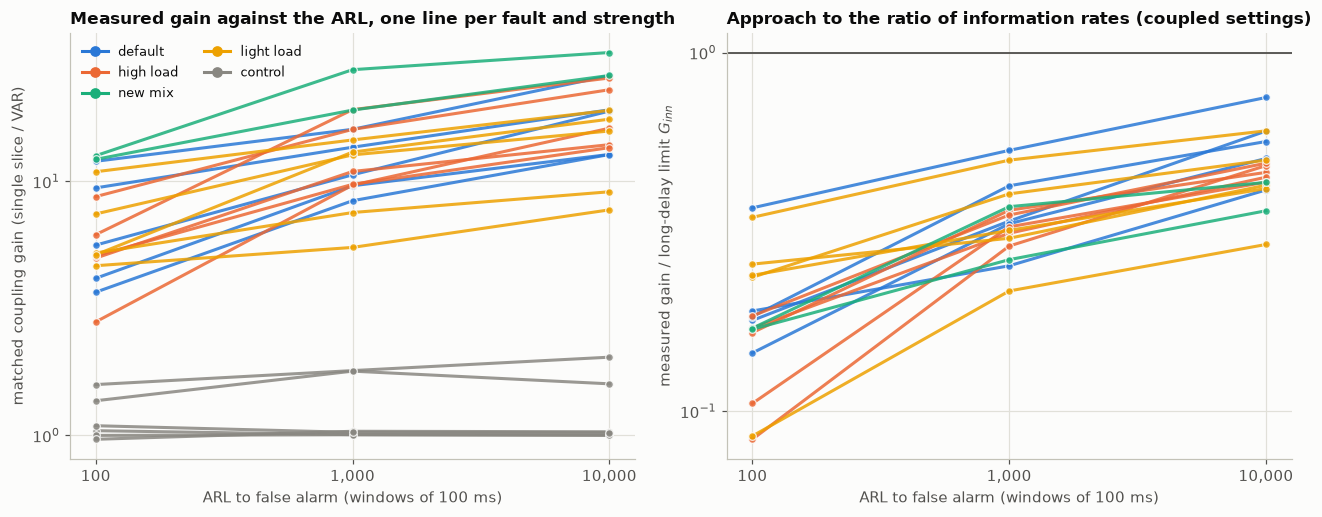

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
for (n, scen, s), r in trend.iterrows():
    ax.plot(ARLS, [r[a] for a in ARLS], marker="o", color=COLOR[n], alpha=0.85, ms=5, mec=SURFACE, mew=0.8)
for n in SETTINGS:
    ax.plot([], [], "o-", color=COLOR[n], label=NICE_SET[n])
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(ARLS, [f"{a:,}" for a in ARLS]); ax.minorticks_off()
ax.set_xlabel("ARL to false alarm (windows of 100 ms)")
ax.set_ylabel("matched coupling gain (single slice / VAR)")
ax.set_title("Measured gain against the ARL, one line per fault and strength")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)

ax = axes[1]
for (n, scen, s), r in trend.iterrows():
    if n == "control":
        continue
    ax.plot(ARLS, [r[a] / r.G_inn for a in ARLS], marker="o", color=COLOR[n], alpha=0.85, ms=5, mec=SURFACE, mew=0.8)
ax.axhline(1, color=INK2, lw=1.2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(ARLS, [f"{a:,}" for a in ARLS]); ax.minorticks_off()
ax.set_xlabel("ARL to false alarm (windows of 100 ms)")
ax.set_ylabel(r"measured gain / long-delay limit $G_{inn}$")
ax.set_title("Approach to the ratio of information rates (coupled settings)")
fig.tight_layout()
save_fig(fig, "fig1_gain_vs_arl")
plt.show()

**What Section 2 shows: P1 and P3 hold**

- **Usable cases.** 23 cases reach every ARL and are detected at every ARL. The other 22 are faults so strong that the matched reference cannot reach the larger ARLs, or so weak that the single slice misses them at ARL 10 000.
- **P1 holds.** In all 17 coupled cases the gain rises monotonically from ARL 100 to 1000 to 10 000, by a median of 2.64× (range 1.66–5.79×).
- **The rise is somewhat steeper than predicted.** $G_{\text{fin}}$ rises by a median of 2.12×. Most of the difference is at ARL 100, where the measured gain is lower than predicted (Section 3).
- **P3 holds.** In the control, the single-slice faults stay at 0.97–1.09× at every ARL. The weight misconfiguration, which moves two slices, sits at 1.4–2.0×, in line with its no-coupling limit of about 1.8–2.0.
- **The limit is not reached by ARL 10 000** (right panel). The measured gain is a median 0.84 of the Bartlett $G_{\text{DC}}$ and 0.46 of the VAR-implied $G_{\text{inn}}$.
  - In high load and the new mix it has reached the Bartlett estimate (0.94 and 1.23 of it) and is still rising.
  - In light load it is at about half of either limit.
  - Which limit it is heading for cannot be decided from these ARLs, as anticipated in the introduction.

## 3. P2: does the finite-ARL prediction hold at every ARL?

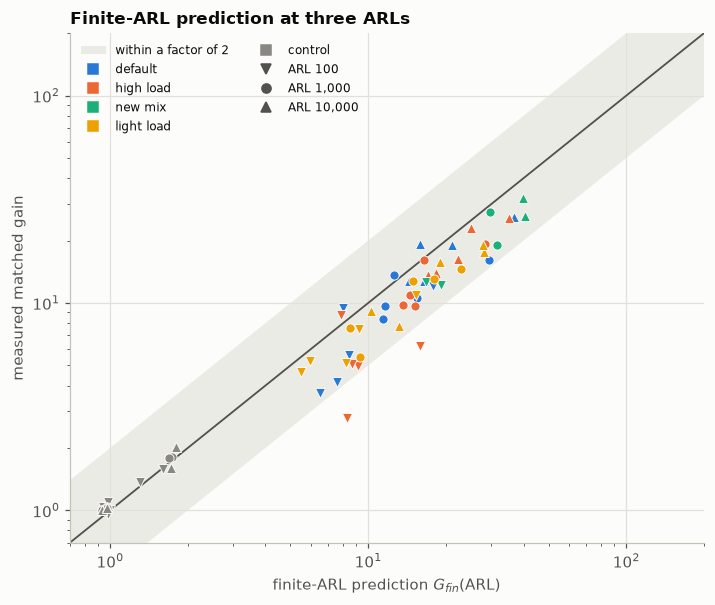

,n,fin_median,fin_min,fin_max,fin_within2,dc_median,dc_within2
arl,,,,,,,
100,23,0.76,0.34,1.18,21,0.35,8
1000,23,0.83,0.54,1.09,23,0.65,16
10000,23,0.83,0.59,1.21,23,0.92,20


In [5]:
use["ratio_fin"] = use.gain / use.G_fin
use["ratio_dc"] = use.gain / use.G_dc
P2 = use.groupby("arl").agg(n=("ratio_fin", "size"),
                            fin_median=("ratio_fin", "median"), fin_min=("ratio_fin", "min"), fin_max=("ratio_fin", "max"),
                            fin_within2=("ratio_fin", lambda q: int(((q > 0.5) & (q < 2)).sum())),
                            dc_median=("ratio_dc", "median"),
                            dc_within2=("ratio_dc", lambda q: int(((q > 0.5) & (q < 2)).sum())))
P2.to_csv(OUT / "p2.csv")

fig, ax = plt.subplots(figsize=(6.6, 5.6))
lo, hi = 0.7, 200
xs = np.array([lo, hi])
ax.fill_between(xs, xs / 2, xs * 2, color=GRID, alpha=0.6, lw=0, label="within a factor of 2")
ax.plot(xs, xs, color=INK2, lw=1.2)
MARK = dict(zip(ARLS, ["v", "o", "^"]))
for n in SETTINGS:
    for a in ARLS:
        g = use[(use.setting == n) & (use.arl == a)]
        ax.plot(g.G_fin, g.gain, MARK[a], color=COLOR[n], ms=6, mec=SURFACE, mew=0.6)
for n in SETTINGS:
    ax.plot([], [], "s", color=COLOR[n], label=NICE_SET[n])
for a in ARLS:
    ax.plot([], [], MARK[a], color=INK2, label=f"ARL {a:,}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel(r"finite-ARL prediction $G_{fin}$(ARL)")
ax.set_ylabel("measured matched gain")
ax.set_title("Finite-ARL prediction at three ARLs")
ax.legend(loc="upper left", fontsize=8, ncol=2)
fig.tight_layout()
save_fig(fig, "fig2_prediction_by_arl")
plt.show()
P2.round(2)

**What Section 3 shows: P2 holds at ARL 1000 and 10 000, and fails in 2 of 23 cases at ARL 100**

- **The finite-ARL prediction is within a factor of 2 in 23 of 23 cases at ARL 1000 and at 10 000,** with median measured/predicted 0.83 at both.
- **At ARL 100 it holds in 21 of 23** (median 0.76). The two failures are high-load cases: mMTC storm at $s = 0.25$ (0.34) and weight misconfiguration at $s = 0.1$ (0.39).
  - At ARL 100 the threshold is so low that the CUSUM's excursions are only a few windows long.
  - There Siegmund's approximation and the long-run (Brownian) treatment of autocorrelated noise are least accurate.
  - So P2 as stated ("at every ARL") is not fully confirmed.
- **The asymptotic ratio improves steadily with the ARL,** as expected: median measured/$G_{\text{DC}}$ is 0.35, 0.65 and 0.92, within a factor of 2 in 8, 16 and 20 of 23 cases. It becomes a usable prediction only for long delays.

In [6]:
# Export tables and key numbers for report/main.tex
f1 = lambda v: "--" if pd.isna(v) else f"{v:.1f}"
f2 = lambda v: "--" if pd.isna(v) else f"{v:.2f}"
t = trend.reset_index()
t["setting"] = [NICE_SET[v] if i == 0 or v != t.setting.iloc[i - 1] else "" for i, v in enumerate(t.setting)]
t["scenario"] = t.scenario.map(NICE)
t["strength"] = t.strength.map(lambda v: f"{v:g}")
for c in [*ARLS, "G_inn", "G_dc"]:
    t[c] = t[c].map(f1)
t["rises"] = t.rises.map({True: "yes", False: "no"})
t = t[["setting", "scenario", "strength", *ARLS, "G_inn", "G_dc", "rises"]]
t.columns = ["setting", "fault", "$s$", "ARL 100", "ARL 1000", "ARL 10\\,000", "$G_{\\mathrm{inn}}$",
             "$G_{\\mathrm{DC}}$", "rises"]
save_tex_table(t, "trend", "lllrrrrrc")

t = P2.reset_index()
t["arl"] = t.arl.map(lambda v: f"{v:,}".replace(",", "\\,"))
t["fin"] = [f"{w}/{n}" for w, n in zip(P2.fin_within2, P2.n)]
t["dc"] = [f"{w}/{n}" for w, n in zip(P2.dc_within2, P2.n)]
for c in ["fin_median", "fin_min", "fin_max", "dc_median"]:
    t[c] = t[c].map(f2)
t = t[["arl", "fin_median", "fin_min", "fin_max", "fin", "dc_median", "dc"]]
t.columns = ["ARL", "median", "min", "max", "within $\\times 2$", "median", "within $\\times 2$"]
save_tex_table(t, "p2", "lrrrrrr")

save_tex_numbers({
    "AsCases": f"{len(trend)}", "AsCoupled": f"{len(coupled)}", "AsRises": f"{int(coupled.rises.sum())}",
    "AsRiseMedian": f2(coupled.rise_100_to_10000.median()),
    "AsRiseMin": f2(coupled.rise_100_to_10000.min()), "AsRiseMax": f2(coupled.rise_100_to_10000.max()),
    "AsPredRiseMedian": f2(coupled.predicted_rise.median()),
    "AsCtrlMin": f2(control[ARLS].min().min()), "AsCtrlMax": f2(control[ARLS].max().max()),
    **{f"AsFinWithin{k}": f"{P2.loc[a, 'fin_within2']}" for k, a in zip(["A", "B", "C"], ARLS)},
    **{f"AsFinMedian{k}": f2(P2.loc[a, "fin_median"]) for k, a in zip(["A", "B", "C"], ARLS)},
    **{f"AsDcMedian{k}": f2(P2.loc[a, "dc_median"]) for k, a in zip(["A", "B", "C"], ARLS)},
    "AsLimInnMedianC": f2((coupled[ARLS[-1]] / coupled.G_inn).median()),
    "AsLimDcMedianC": f2((coupled[ARLS[-1]] / coupled.G_dc).median()),
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("13_*")))

exported: ['13_numbers.tex', '13_p2.tex', '13_trend.tex']


## Summary

- **The ARL sweep confirms the finite-ARL explanation of notebook 12.** Two of three pre-registered predictions hold fully, and the third holds except at the smallest ARL:
  - **P1:** the matched coupling gain rises with the ARL in 17 of 17 coupled cases (median ×2.64 from ARL 100 to 10 000).
  - **P2:** the finite-ARL prediction is within ×2 at ARL 1000 and 10 000 in 23 of 23 cases, and at ARL 100 in 21 of 23. It fails at the shortest delays.
  - **P3:** the control stays at its no-coupling value at every ARL.
- **Consequence for the rule.**
  - The zero-frequency information rates set both detectors' delays, and the coupling gain grows with the ARL towards their ratio.
  - At ARL 100 the realised gain is about a third of the asymptotic ratio; at ARL 10 000 it is about 0.9 of the Bartlett estimate.
  - For design, the gain should be predicted at the operating ARL. $1/(1-R^2_{\text{DC}})$ is what a long false-alarm interval buys.
- **Open:**
  - which estimate of the limit is right (Bartlett or VAR-implied), since by ARL 10 000 the gain has not stopped rising in two settings;
  - the accuracy of the finite-ARL prediction at very small ARLs;
  - all of this for oracle detectors only, in simulation.